In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("../data/Ds_Data.csv")

In [3]:
df.head()

,destination,passanger,weather,temperature,coupon,expiration,gender,age,maritalStatus,has_children,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Accept(Y/N?)
0,No Urgent Place,Alone,Sunny,55,Restaurant(<20),1d,Female,21,Unmarried partner,1,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,Coffee House,2h,Female,21,Unmarried partner,1,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,Carry out & Take away,2h,Female,21,Unmarried partner,1,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,Coffee House,2h,Female,21,Unmarried partner,1,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,Coffee House,1d,Female,21,Unmarried partner,1,...,never,NaN,4~8,1~3,1,1,0,0,1,0


In [4]:
df.shape

(12684, 25)

In [5]:
df.columns.tolist()

['destination',
 'passanger',
 'weather',
 'temperature',
 'coupon',
 'expiration',
 'gender',
 'age',
 'maritalStatus',
 'has_children',
 'education',
 'occupation',
 'income',
 'car',
 'Bar',
 'CoffeeHouse',
 'CarryAway',
 'RestaurantLessThan20',
 'Restaurant20To50',
 'toCoupon_GEQ5min',
 'toCoupon_GEQ15min',
 'toCoupon_GEQ25min',
 'direction_same',
 'direction_opp',
 'Accept(Y/N?)']

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   destination           12684 non-null  str  
 1   passanger             12684 non-null  str  
 2   weather               12684 non-null  str  
 3   temperature           12684 non-null  int64
 4   coupon                12684 non-null  str  
 5   expiration            12684 non-null  str  
 6   gender                12684 non-null  str  
 7   age                   12684 non-null  str  
 8   maritalStatus         12684 non-null  str  
 9   has_children          12684 non-null  int64
 10  education             12684 non-null  str  
 11  occupation            12684 non-null  str  
 12  income                12684 non-null  str  
 13  car                   108 non-null    str  
 14  Bar                   12577 non-null  str  
 15  CoffeeHouse           12467 non-null  str  
 16  CarryAway      

In [7]:
df.isnull().sum()

destination                 0
passanger                   0
weather                     0
temperature                 0
coupon                      0
expiration                  0
gender                      0
age                         0
maritalStatus               0
has_children                0
education                   0
occupation                  0
income                      0
car                     12576
Bar                       107
CoffeeHouse               217
CarryAway                 151
RestaurantLessThan20      130
Restaurant20To50          189
toCoupon_GEQ5min            0
toCoupon_GEQ15min           0
toCoupon_GEQ25min           0
direction_same              0
direction_opp               0
Accept(Y/N?)                0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(291)

In [9]:
df["Accept(Y/N?)"].unique()

array([1, 0])

In [10]:
df["Accept(Y/N?)"].value_counts()

Accept(Y/N?)
1    7210
0    5474
Name: count, dtype: int64

In [11]:
df["Accept(Y/N?)"].value_counts(normalize=True) * 100

Accept(Y/N?)
1    56.843267
0    43.156733
Name: proportion, dtype: float64

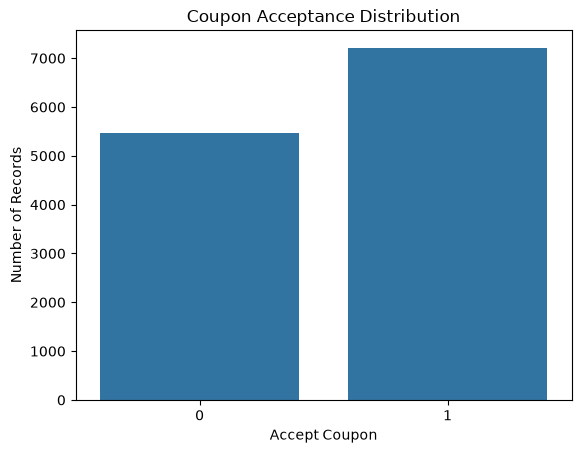

In [12]:
sns.countplot(data=df, x="Accept(Y/N?)")

plt.title("Coupon Acceptance Distribution")
plt.xlabel("Accept Coupon")
plt.ylabel("Number of Records")

plt.show()

DATA CLEANING

In [13]:
df_clean = df.copy()

In [16]:
print("Before removing duplicates:", df_clean.shape)

print("Duplicate rows:", df_clean.duplicated().sum())

Before removing duplicates: (12393, 25)
Duplicate rows: 0


In [17]:
df_clean = df_clean.drop_duplicates()

In [18]:
print("After removing duplicates:", df_clean.shape)
print("Remaining duplicates:", df_clean.duplicated().sum())

After removing duplicates: (12393, 25)
Remaining duplicates: 0


In [19]:
df_clean.isnull().sum()

destination                 0
passanger                   0
weather                     0
temperature                 0
coupon                      0
expiration                  0
gender                      0
age                         0
maritalStatus               0
has_children                0
education                   0
occupation                  0
income                      0
car                     12287
Bar                       106
CoffeeHouse               215
CarryAway                 148
RestaurantLessThan20      128
Restaurant20To50          188
toCoupon_GEQ5min            0
toCoupon_GEQ15min           0
toCoupon_GEQ25min           0
direction_same              0
direction_opp               0
Accept(Y/N?)                0
dtype: int64

In [20]:
df_clean = df_clean.drop(columns=["car"])

In [21]:
df_clean.shape

(12393, 24)

In [22]:
for column in ["Bar", "CoffeeHouse", "CarryAway",
               "RestaurantLessThan20", "Restaurant20To50"]:
    print("\n", column)
    print(df_clean[column].value_counts(dropna=False))


 Bar
Bar
never    5089
less1    3383
1~3      2432
4~8      1045
gt8       338
NaN       106
Name: count, dtype: int64

 CoffeeHouse
CoffeeHouse
less1    3310
1~3      3138
never    2895
4~8      1752
gt8      1083
NaN       215
Name: count, dtype: int64

 CarryAway
CarryAway
1~3      4571
4~8      4171
less1    1819
gt8      1535
never     149
NaN       148
Name: count, dtype: int64

 RestaurantLessThan20
RestaurantLessThan20
1~3      5269
4~8      3493
less1    2034
gt8      1253
never     216
NaN       128
Name: count, dtype: int64

 Restaurant20To50
Restaurant20To50
less1    5946
1~3      3204
never    2083
4~8       718
gt8       254
NaN       188
Name: count, dtype: int64


In [23]:
columns_to_fill = [
    "Bar",
    "CoffeeHouse",
    "CarryAway",
    "RestaurantLessThan20",
    "Restaurant20To50"
]

for column in columns_to_fill:
    mode_value = df_clean[column].mode()[0]
    print(column, "→", mode_value)

Bar → never
CoffeeHouse → less1
CarryAway → 1~3
RestaurantLessThan20 → 1~3
Restaurant20To50 → less1


In [24]:
df_clean[columns_to_fill].isnull().sum()

Bar                     106
CoffeeHouse             215
CarryAway               148
RestaurantLessThan20    128
Restaurant20To50        188
dtype: int64

In [25]:
for column in columns_to_fill:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].mode()[0]
    )

In [26]:
df_clean.isnull().sum()

destination             0
passanger               0
weather                 0
temperature             0
coupon                  0
expiration              0
gender                  0
age                     0
maritalStatus           0
has_children            0
education               0
occupation              0
income                  0
Bar                     0
CoffeeHouse             0
CarryAway               0
RestaurantLessThan20    0
Restaurant20To50        0
toCoupon_GEQ5min        0
toCoupon_GEQ15min       0
toCoupon_GEQ25min       0
direction_same          0
direction_opp           0
Accept(Y/N?)            0
dtype: int64

In [27]:
df_clean.to_csv("../data/cleaned/cleaned_coupon_data.csv", index=False)


In [28]:
print("Shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

Shape: (12393, 24)
Missing values: 0
Duplicate rows: 0


EDA

In [29]:
df_clean["coupon"].value_counts()

coupon
Coffee House             3913
Restaurant(<20)          2708
Carry out & Take away    2275
Bar                      2010
Restaurant(20-50)        1487
Name: count, dtype: int64

In [30]:
coupon_acceptance = (
    df_clean.groupby("coupon")["Accept(Y/N?)"]
    .mean()
    .sort_values(ascending=False)
    * 100
)

coupon_acceptance

coupon
Carry out & Take away    73.186813
Restaurant(<20)          71.048744
Coffee House             49.654996
Restaurant(20-50)        44.115669
Bar                      40.995025
Name: Accept(Y/N?), dtype: float64

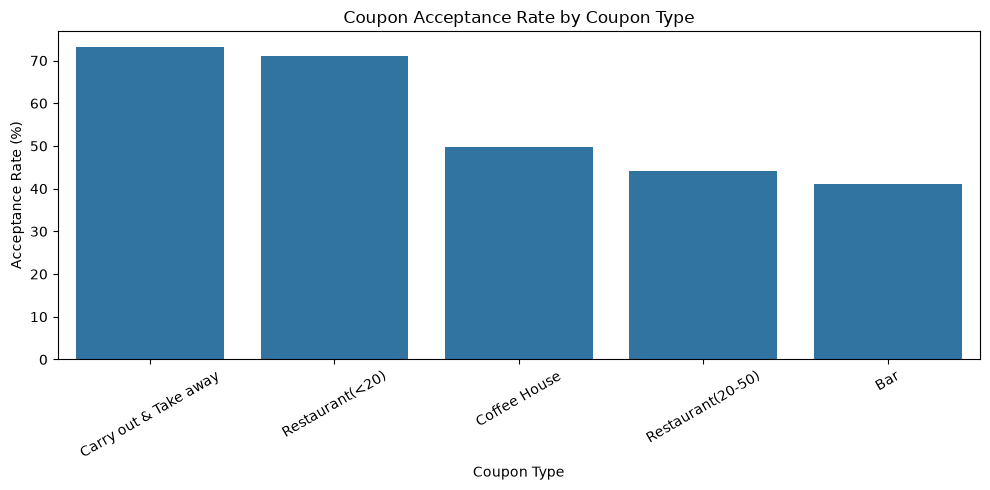

In [31]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=coupon_acceptance.index,
    y=coupon_acceptance.values
)

plt.title("Coupon Acceptance Rate by Coupon Type")
plt.xlabel("Coupon Type")
plt.ylabel("Acceptance Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Age vs Coupon Acceptance

In [32]:
df_clean["age"].value_counts()

age
21         2598
26         2486
31         1984
50plus     1756
36         1293
41         1079
46          660
below21     537
Name: count, dtype: int64

In [33]:
age_acceptance = (
    df_clean.groupby("age")["Accept(Y/N?)"]
    .mean()
    .sort_values(ascending=False)
    * 100
)

age_acceptance

age
below21    62.942272
21         59.622787
26         59.332261
41         57.275255
46         57.272727
31         54.385081
36         53.132251
50plus     50.569476
Name: Accept(Y/N?), dtype: float64

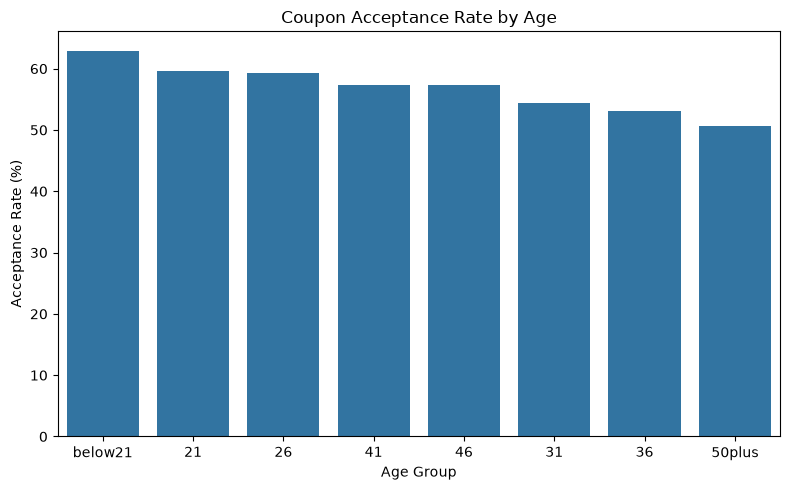

In [34]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=age_acceptance.index,
    y=age_acceptance.values
)

plt.title("Coupon Acceptance Rate by Age")
plt.xlabel("Age Group")
plt.ylabel("Acceptance Rate (%)")
plt.tight_layout()
plt.show()

Gender vs Coupon Acceptance

In [35]:
df_clean["gender"].value_counts()

gender
Female    6355
Male      6038
Name: count, dtype: int64

In [36]:
gender_acceptance = (
    df_clean.groupby("gender")["Accept(Y/N?)"]
    .mean()
    .sort_values(ascending=False)
    * 100
)

gender_acceptance

gender
Male      58.827426
Female    54.445319
Name: Accept(Y/N?), dtype: float64

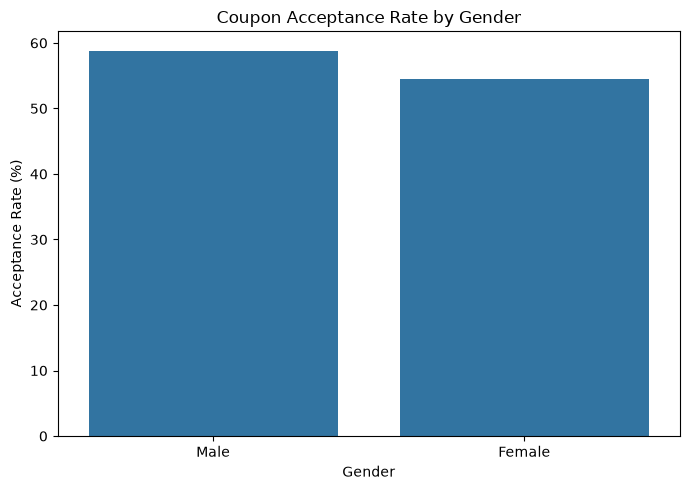

In [37]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=gender_acceptance.index,
    y=gender_acceptance.values
)

plt.title("Coupon Acceptance Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Acceptance Rate (%)")
plt.tight_layout()
plt.show()

Income vs Coupon Acceptance

In [38]:
df_clean["income"].value_counts()

income
$25000 - $37499     1972
$12500 - $24999     1795
$37500 - $49999     1760
$100000 or More     1688
$50000 - $62499     1624
Less than $12500    1013
$87500 - $99999      865
$75000 - $87499      844
$62500 - $74999      832
Name: count, dtype: int64

In [39]:
income_acceptance = (
    df_clean.groupby("income")["Accept(Y/N?)"]
    .mean()
    .sort_values(ascending=False)
    * 100
)

income_acceptance

income
$50000 - $62499     59.359606
$25000 - $37499     59.077079
Less than $12500    58.538993
$100000 or More     57.701422
$12500 - $24999     57.325905
$37500 - $49999     56.079545
$87500 - $99999     52.716763
$62500 - $74999     52.524038
$75000 - $87499     48.222749
Name: Accept(Y/N?), dtype: float64

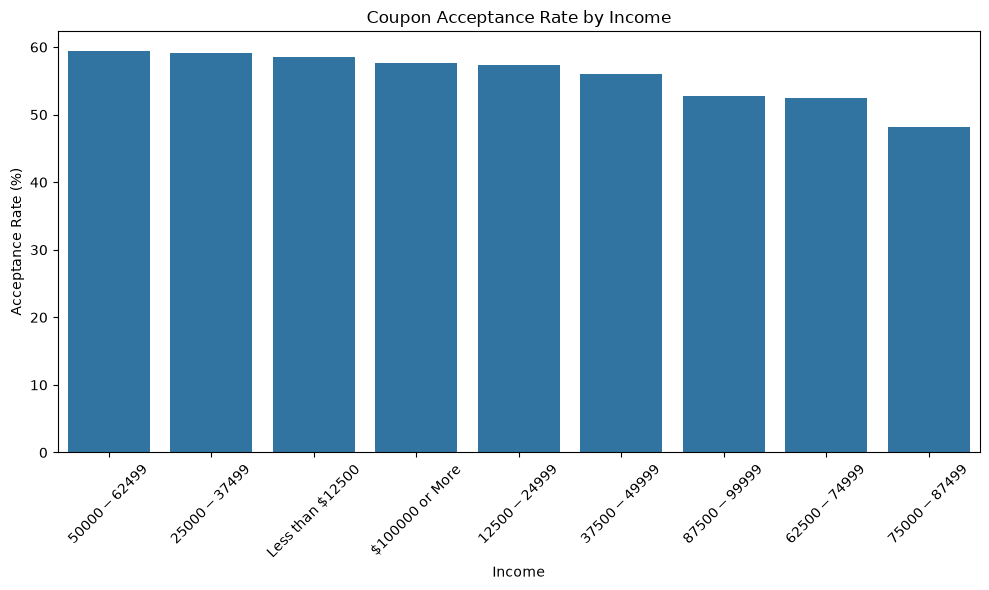

In [40]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=income_acceptance.index,
    y=income_acceptance.values
)

plt.title("Coupon Acceptance Rate by Income")
plt.xlabel("Income")
plt.ylabel("Acceptance Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Weather

In [41]:
df_clean["weather"].value_counts()

weather
Sunny    9862
Snowy    1329
Rainy    1202
Name: count, dtype: int64

In [42]:
weather_acceptance = (
    df_clean.groupby("weather")["Accept(Y/N?)"]
    .mean()
    .sort_values(ascending=False)
    * 100
)

weather_acceptance

weather
Sunny    59.318597
Rainy    46.339434
Snowy    45.522950
Name: Accept(Y/N?), dtype: float64

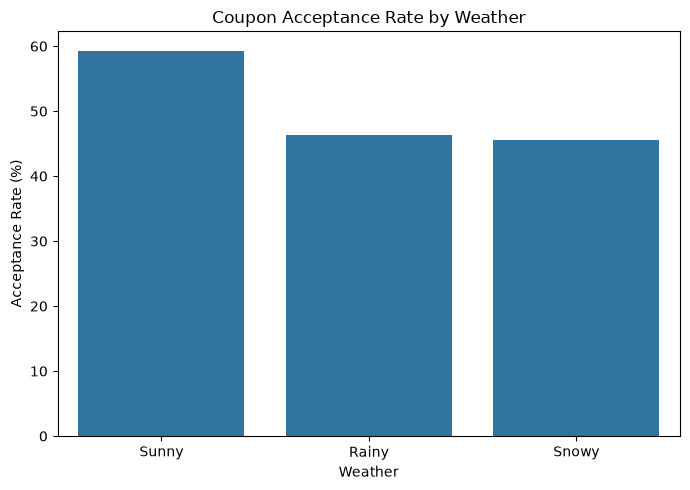

In [43]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=weather_acceptance.index,
    y=weather_acceptance.values
)

plt.title("Coupon Acceptance Rate by Weather")
plt.xlabel("Weather")
plt.ylabel("Acceptance Rate (%)")
plt.tight_layout()
plt.show()

Expiration vs Acceptance

In [44]:
df_clean["expiration"].value_counts()

expiration
1d    6938
2h    5455
Name: count, dtype: int64

In [45]:
expiration_acceptance = (
    df_clean.groupby("expiration")["Accept(Y/N?)"]
    .mean()
    .sort_values(ascending=False)
    * 100
)

expiration_acceptance

expiration
1d    62.222543
2h    49.404216
Name: Accept(Y/N?), dtype: float64

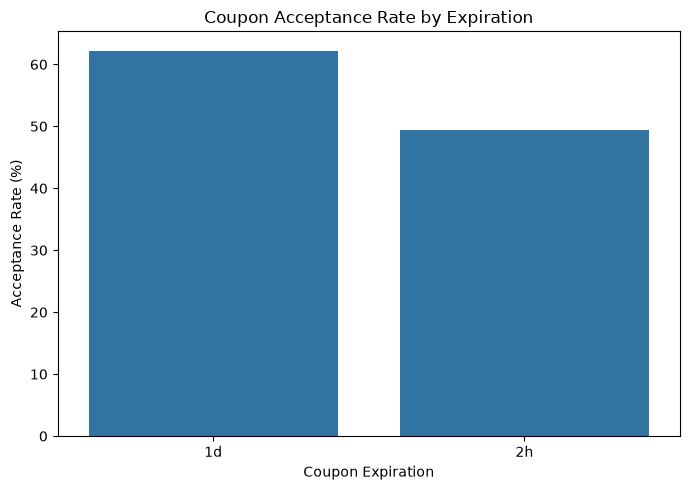

In [46]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=expiration_acceptance.index,
    y=expiration_acceptance.values
)

plt.title("Coupon Acceptance Rate by Expiration")
plt.xlabel("Coupon Expiration")
plt.ylabel("Acceptance Rate (%)")
plt.tight_layout()
plt.show()

Destination

In [47]:
df_clean["destination"].value_counts()

destination
No Urgent Place    6118
Home               3161
Work               3114
Name: count, dtype: int64

In [48]:
destination_acceptance = (
    df_clean.groupby("destination")["Accept(Y/N?)"]
    .mean()
    .sort_values(ascending=False)
    * 100
)

destination_acceptance

destination
No Urgent Place    63.174240
Home               50.427080
Work               49.871548
Name: Accept(Y/N?), dtype: float64

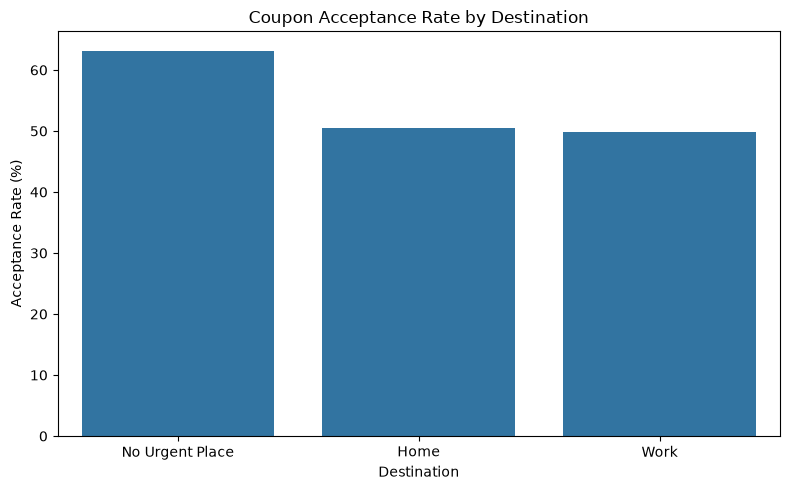

In [49]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=destination_acceptance.index,
    y=destination_acceptance.values
)

plt.title("Coupon Acceptance Rate by Destination")
plt.xlabel("Destination")
plt.ylabel("Acceptance Rate (%)")
plt.tight_layout()
plt.show()

Passenger Type

In [50]:
df_clean["passanger"].value_counts()

passanger
Alone        7178
Friend(s)    3166
Partner      1068
Kid(s)        981
Name: count, dtype: int64

In [51]:
passenger_acceptance = (
    df_clean.groupby("passanger")["Accept(Y/N?)"]
    .mean()
    .sort_values(ascending=False)
    * 100
)

passenger_acceptance

passanger
Friend(s)    67.182565
Partner      59.363296
Alone        52.382279
Kid(s)       50.050968
Name: Accept(Y/N?), dtype: float64

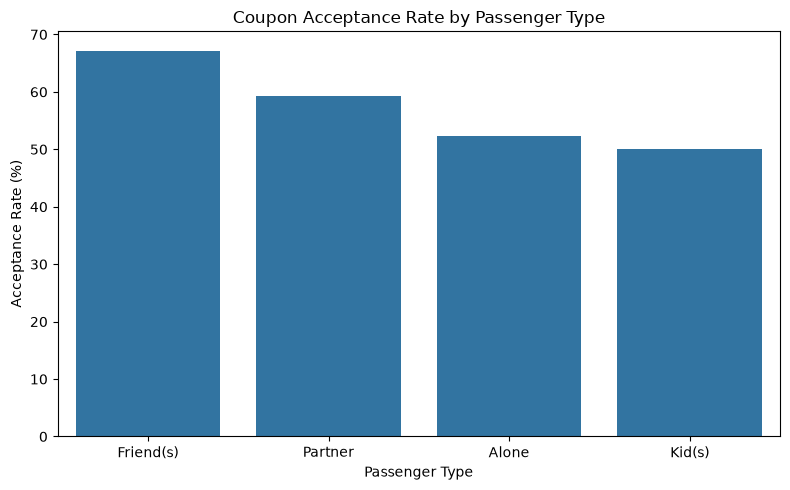

In [52]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=passenger_acceptance.index,
    y=passenger_acceptance.values
)

plt.title("Coupon Acceptance Rate by Passenger Type")
plt.xlabel("Passenger Type")
plt.ylabel("Acceptance Rate (%)")
plt.tight_layout()
plt.show()

CoffeeHouse Behavior

In [53]:
coffee_acceptance = (
    df_clean.groupby("CoffeeHouse")["Accept(Y/N?)"]
    .mean()
    .sort_values(ascending=False)
    * 100
)

coffee_acceptance

CoffeeHouse
1~3      65.137030
4~8      63.184932
gt8      58.264081
less1    54.212766
never    45.561313
Name: Accept(Y/N?), dtype: float64

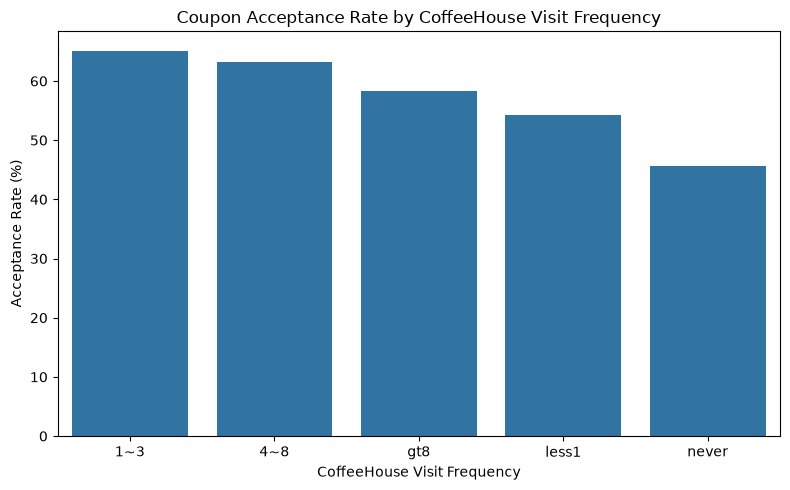

In [54]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=coffee_acceptance.index,
    y=coffee_acceptance.values
)

plt.title("Coupon Acceptance Rate by CoffeeHouse Visit Frequency")
plt.xlabel("CoffeeHouse Visit Frequency")
plt.ylabel("Acceptance Rate (%)")
plt.tight_layout()
plt.show()

Bar Visit Frequency

In [55]:
bar_acceptance = (
    df_clean.groupby("Bar")["Accept(Y/N?)"]
    .mean()
    .sort_values(ascending=False)
    * 100
)

bar_acceptance

Bar
4~8      63.253589
1~3      62.006579
gt8      57.988166
less1    56.222288
never    52.839269
Name: Accept(Y/N?), dtype: float64

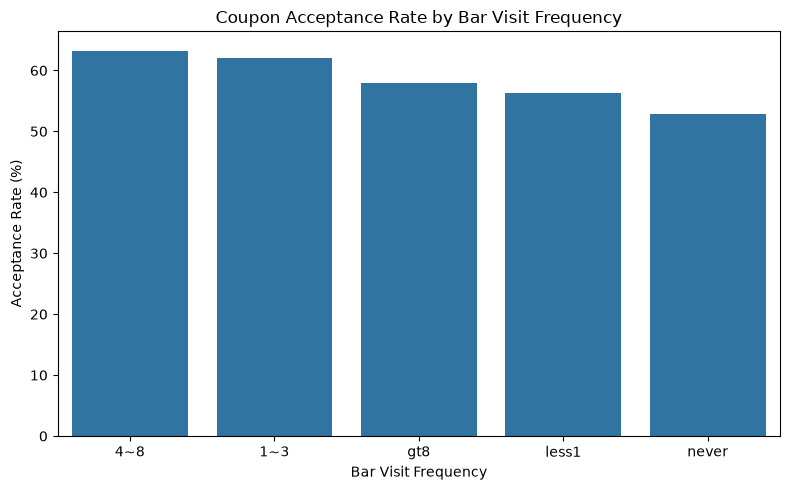

In [56]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=bar_acceptance.index,
    y=bar_acceptance.values
)

plt.title("Coupon Acceptance Rate by Bar Visit Frequency")
plt.xlabel("Bar Visit Frequency")
plt.ylabel("Acceptance Rate (%)")
plt.tight_layout()
plt.show()

CarryAway

In [57]:
carryaway_acceptance = (
    df_clean.groupby("CarryAway")["Accept(Y/N?)"]
    .mean()
    .sort_values(ascending=False)
    * 100
)

carryaway_acceptance

CarryAway
1~3      58.126722
4~8      57.755934
gt8      57.068404
never    52.348993
less1    49.807587
Name: Accept(Y/N?), dtype: float64

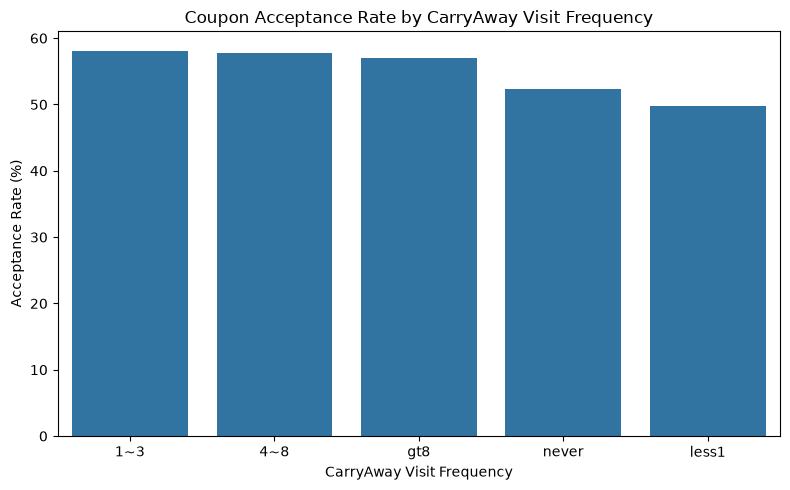

In [58]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=carryaway_acceptance.index,
    y=carryaway_acceptance.values
)

plt.title("Coupon Acceptance Rate by CarryAway Visit Frequency")
plt.xlabel("CarryAway Visit Frequency")
plt.ylabel("Acceptance Rate (%)")
plt.tight_layout()
plt.show()

Restaurant Visits Under $20

In [59]:
restaurant20_acceptance = (
    df_clean.groupby("RestaurantLessThan20")["Accept(Y/N?)"]
    .mean()
    .sort_values(ascending=False)
    * 100
)

restaurant20_acceptance

RestaurantLessThan20
gt8      60.574621
4~8      58.173490
1~3      56.031128
never    53.240741
less1    53.195674
Name: Accept(Y/N?), dtype: float64

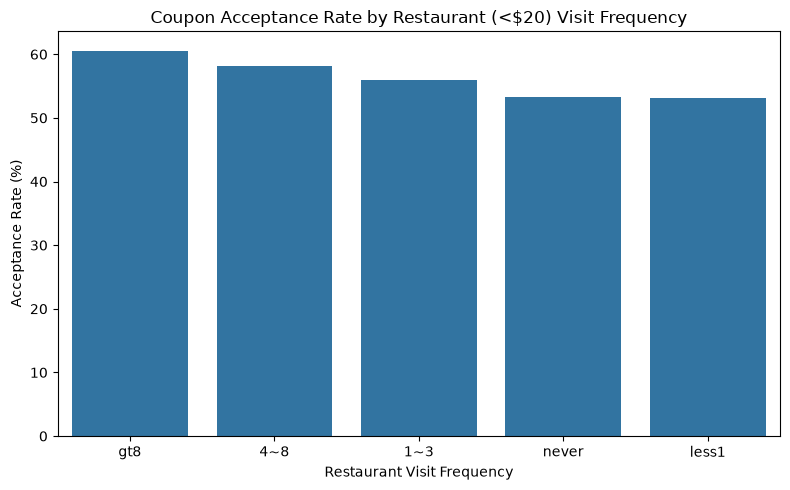

In [60]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=restaurant20_acceptance.index,
    y=restaurant20_acceptance.values
)

plt.title("Coupon Acceptance Rate by Restaurant (<$20) Visit Frequency")
plt.xlabel("Restaurant Visit Frequency")
plt.ylabel("Acceptance Rate (%)")
plt.tight_layout()
plt.show()

Restaurant20To50

In [61]:
restaurant50_acceptance = (
    df_clean.groupby("Restaurant20To50")["Accept(Y/N?)"]
    .mean()
    .sort_values(ascending=False)
    * 100
)

restaurant50_acceptance

Restaurant20To50
gt8      66.929134
4~8      65.459610
1~3      59.144819
less1    55.542876
never    51.368219
Name: Accept(Y/N?), dtype: float64

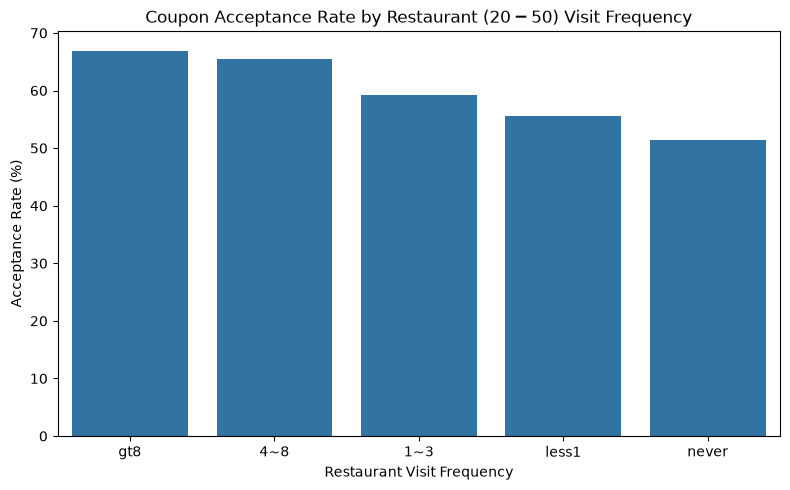

In [62]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=restaurant50_acceptance.index,
    y=restaurant50_acceptance.values
)

plt.title("Coupon Acceptance Rate by Restaurant ($20-$50) Visit Frequency")
plt.xlabel("Restaurant Visit Frequency")
plt.ylabel("Acceptance Rate (%)")
plt.tight_layout()
plt.show()

end

Target we find

In [63]:
y = df_clean["Accept(Y/N?)"]

In [64]:
X = df_clean.drop(columns=["Accept(Y/N?)"])

In [65]:
df_clean.dtypes

destination               str
passanger                 str
weather                   str
temperature             int64
coupon                    str
expiration                str
gender                    str
age                       str
maritalStatus             str
has_children            int64
education                 str
occupation                str
income                    str
Bar                       str
CoffeeHouse               str
CarryAway                 str
RestaurantLessThan20      str
Restaurant20To50          str
toCoupon_GEQ5min        int64
toCoupon_GEQ15min       int64
toCoupon_GEQ25min       int64
direction_same          int64
direction_opp           int64
Accept(Y/N?)            int64
dtype: object

In [66]:
df_clean.nunique().sort_values()

toCoupon_GEQ5min         1
Accept(Y/N?)             2
direction_same           2
toCoupon_GEQ25min        2
toCoupon_GEQ15min        2
expiration               2
gender                   2
direction_opp            2
has_children             2
destination              3
temperature              3
weather                  3
passanger                4
Bar                      5
CoffeeHouse              5
CarryAway                5
RestaurantLessThan20     5
Restaurant20To50         5
coupon                   5
maritalStatus            5
education                6
age                      8
income                   9
occupation              25
dtype: int64

In [67]:
pd.get_dummies(df_clean)

,temperature,has_children,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Accept(Y/N?),destination_Home,destination_No Urgent Place,...,RestaurantLessThan20_1~3,RestaurantLessThan20_4~8,RestaurantLessThan20_gt8,RestaurantLessThan20_less1,RestaurantLessThan20_never,Restaurant20To50_1~3,Restaurant20To50_4~8,Restaurant20To50_gt8,Restaurant20To50_less1,Restaurant20To50_never
0,55,1,1,0,0,0,1,1,False,True,...,False,True,False,False,False,True,False,False,False,False
1,80,1,1,0,0,0,1,0,False,True,...,False,True,False,False,False,True,False,False,False,False
2,80,1,1,1,0,0,1,1,False,True,...,False,True,False,False,False,True,False,False,False,False
3,80,1,1,1,0,0,1,0,False,True,...,False,True,False,False,False,True,False,False,False,False
4,80,1,1,1,0,0,1,0,False,True,...,False,True,False,False,False,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12679,55,0,1,0,0,1,0,1,True,False,...,False,True,False,False,False,True,False,False,False,False
12680,55,0,1,0,0,0,1,1,False,False,...,False,True,False,False,False,True,False,False,False,False
12681,30,0,1,0,0,1,0,0,False,False,...,False,True,False,False,False,True,False,False,False,False
12682,30,0,1,1,1,0,1,0,False,False,...,False,True,False,False,False,True,False,False,False,False


In [68]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (12393, 23)
y shape: (12393,)


Numerical columns

In [70]:
numeric_features = [
    "temperature",
    "has_children",
    "toCoupon_GEQ5min",
    "toCoupon_GEQ15min",
    "toCoupon_GEQ25min",
    "direction_same",
    "direction_opp"
]

Categorical columns

In [71]:
categorical_features = [
    "destination",
    "passanger",
    "weather",
    "coupon",
    "expiration",
    "gender",
    "age",
    "maritalStatus",
    "education",
    "occupation",
    "income",
    "Bar",
    "CoffeeHouse",
    "CarryAway",
    "RestaurantLessThan20",
    "Restaurant20To50"
]

Train/Test Split

In [72]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

Check the split

In [73]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target:")
print(y_train.value_counts(normalize=True))

print("\nTesting target:")
print(y_test.value_counts(normalize=True))

Training data: (9914, 23)
Testing data: (2479, 23)

Training target:
Accept(Y/N?)
1    0.565766
0    0.434234
Name: proportion, dtype: float64

Testing target:
Accept(Y/N?)
1    0.565954
0    0.434046
Name: proportion, dtype: float64


 X and Y

In [74]:
X = df_clean.drop(columns=["Accept(Y/N?)"])
y = df_clean["Accept(Y/N?)"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (12393, 23)
y shape: (12393,)


In [75]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (9914, 23)
Testing: (2479, 23)


Encoding

In [76]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor

In [77]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", StandardScaler(), numeric_features)
    ]
)

Fit on training data only

In [78]:
X_train_encoded = preprocessor.fit_transform(X_train)

X_test_encoded = preprocessor.transform(X_test)

In [79]:
print("Original training shape:", X_train.shape)
print("Encoded training shape:", X_train_encoded.shape)

print("Original testing shape:", X_test.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Original training shape: (9914, 23)
Encoded training shape: (9914, 104)
Original testing shape: (2479, 23)
Encoded testing shape: (2479, 104)


Train Our First ML Model

1 Logistic Regression

In [80]:
from sklearn.linear_model import LogisticRegression

In [81]:
model_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [82]:
model_lr.fit(X_train_encoded, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [83]:
y_pred_lr = model_lr.predict(X_test_encoded)

In [84]:
from sklearn.metrics import accuracy_score

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy_lr)
print("Accuracy (%):", accuracy_lr * 100)

Logistic Regression Accuracy: 0.6833400564743848
Accuracy (%): 68.33400564743847


In [85]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)

print(cm)

[[ 624  452]
 [ 333 1070]]


In [88]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_encoded, y_train)

y_pred_lr = logistic_model.predict(X_test_encoded)

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Accuracy:", accuracy_lr)
print("Accuracy (%):", accuracy_lr * 100)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

y_pred_proba_lr = logistic_model.predict_proba(X_test_encoded)[:, 1]

roc_auc_lr = roc_auc_score(y_test, y_pred_proba_lr)

print("\nROC-AUC:", roc_auc_lr)
print("ROC-AUC (%):", roc_auc_lr * 100)

Accuracy: 0.6833400564743848
Accuracy (%): 68.33400564743847

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.58      0.61      1076
           1       0.70      0.76      0.73      1403

    accuracy                           0.68      2479
   macro avg       0.68      0.67      0.67      2479
weighted avg       0.68      0.68      0.68      2479


Confusion Matrix:
[[ 624  452]
 [ 333 1070]]

ROC-AUC: 0.7335065327352169
ROC-AUC (%): 73.35065327352169


Decision Tree

In [89]:
from sklearn.tree import DecisionTreeClassifier

In [90]:
model_dt = DecisionTreeClassifier(
    random_state=42
)

In [91]:
model_dt.fit(X_train_encoded, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [92]:
y_pred_dt = model_dt.predict(X_test_encoded)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train_encoded, y_train)

y_pred_dt = dt_model.predict(X_test_encoded)

accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy_dt)
print("Decision Tree Accuracy (%):", accuracy_dt * 100)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

y_pred_proba_dt = dt_model.predict_proba(X_test_encoded)[:, 1]

roc_auc_dt = roc_auc_score(y_test, y_pred_proba_dt)

print("\nDecision Tree ROC-AUC:", roc_auc_dt)
print("Decision Tree ROC-AUC (%):", roc_auc_dt * 100)

Decision Tree Accuracy: 0.6841468334005647
Decision Tree Accuracy (%): 68.41468334005647

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.64      0.64      1076
           1       0.72      0.72      0.72      1403

    accuracy                           0.68      2479
   macro avg       0.68      0.68      0.68      2479
weighted avg       0.68      0.68      0.68      2479


Confusion Matrix:
[[ 690  386]
 [ 397 1006]]

Decision Tree ROC-AUC: 0.6800572723876345
Decision Tree ROC-AUC (%): 68.00572723876344


Random Forest

In [95]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train_encoded, y_train)

y_pred_rf = model_rf.predict(X_test_encoded)

In [96]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)
print("Random Forest Accuracy (%):", accuracy_rf * 100)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Accuracy: 0.7503025413473174
Random Forest Accuracy (%): 75.03025413473175

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.66      0.70      1076
           1       0.76      0.82      0.79      1403

    accuracy                           0.75      2479
   macro avg       0.75      0.74      0.74      2479
weighted avg       0.75      0.75      0.75      2479


Confusion Matrix:
[[ 706  370]
 [ 249 1154]]


ROC-AUC

In [97]:
y_prob_rf = model_rf.predict_proba(X_test_encoded)[:, 1]

roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest ROC-AUC:", roc_auc_rf)

Random Forest ROC-AUC: 0.8089473035741255


In [98]:
feature_names = preprocessor.get_feature_names_out()

importance = model_rf.feature_importances_

feature_importance = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance
    })
    .sort_values("Importance", ascending=False)
)

feature_importance.head(20)

,Feature,Importance
97,num__temperature,0.028626
11,cat__coupon_Carry out & Take away,0.027792
14,cat__coupon_Restaurant(<20),0.027185
100,num__toCoupon_GEQ15min,0.025813
12,cat__coupon_Coffee House,0.025714
10,cat__coupon_Bar,0.024665
81,cat__CoffeeHouse_never,0.021719
15,cat__expiration_1d,0.018888
76,cat__Bar_never,0.018271
16,cat__expiration_2h,0.018100


Hyperparameter Tuning

In [99]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

print(param_grid)

{'n_estimators': [100, 200, 300, 500], 'max_depth': [None, 10, 20, 30], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4], 'max_features': ['sqrt', 'log2']}


In [100]:
rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=param_grid,
    n_iter=20,
    scoring="roc_auc",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [101]:
rf_search.fit(X_train_encoded, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whi

In [102]:
print("Best Parameters:")
print(rf_search.best_params_)

print("\nBest CV ROC-AUC:")
print(rf_search.best_score_)

Best Parameters:
{'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': None}

Best CV ROC-AUC:
0.817333042744741


In [103]:
best_rf = rf_search.best_estimator_

In [104]:
y_pred_best = best_rf.predict(X_test_encoded)

In [105]:
y_prob_best = best_rf.predict_proba(X_test_encoded)[:, 1]

In [106]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

accuracy_best = accuracy_score(y_test, y_pred_best)
roc_auc_best = roc_auc_score(y_test, y_prob_best)

print("Tuned Random Forest Accuracy:", accuracy_best)
print("Tuned Random Forest Accuracy (%):", accuracy_best * 100)

print("\nTuned Random Forest ROC-AUC:", roc_auc_best)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))

Tuned Random Forest Accuracy: 0.7571601452198468
Tuned Random Forest Accuracy (%): 75.71601452198468

Tuned Random Forest ROC-AUC: 0.8156631964960905

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.63      0.69      1076
           1       0.75      0.85      0.80      1403

    accuracy                           0.76      2479
   macro avg       0.76      0.74      0.75      2479
weighted avg       0.76      0.76      0.75      2479


Confusion Matrix:
[[ 681  395]
 [ 207 1196]]


In [107]:
print("Best Parameters:")
print(rf_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(rf_search.best_score_)

Best Parameters:
{'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': None}

Best Cross-Validation ROC-AUC:
0.817333042744741


In [108]:
import joblib

joblib.dump(
    preprocessor,
    "../models/preprocessor.pkl"
)

['../models/preprocessor.pkl']

In [109]:
joblib.dump(
    best_rf,
    "../models/random_forest_coupon_model.pkl"
)

['../models/random_forest_coupon_model.pkl']

In [110]:
loaded_preprocessor = joblib.load(
    "../models/preprocessor.pkl"
)

loaded_model = joblib.load(
    "../models/random_forest_coupon_model.pkl"
)

print("Preprocessor loaded successfully")
print("Model loaded successfully")

Preprocessor loaded successfully
Model loaded successfully


In [111]:
new_customer = pd.DataFrame([{
    "destination": "No Urgent Place",
    "passanger": "Friend(s)",
    "weather": "Sunny",
    "temperature": 80,
    "coupon": "Coffee House",
    "expiration": "1d",
    "gender": "Male",
    "age": "21",
    "maritalStatus": "Single",
    "has_children": 0,
    "education": "Bachelors degree",
    "occupation": "Student",
    "income": "$25000 - $37499",
    "Bar": "never",
    "CoffeeHouse": "1~3",
    "CarryAway": "1~3",
    "RestaurantLessThan20": "1~3",
    "Restaurant20To50": "never",
    "toCoupon_GEQ5min": 1,
    "toCoupon_GEQ15min": 0,
    "toCoupon_GEQ25min": 0,
    "direction_same": 0,
    "direction_opp": 1
}])

print(new_customer)
print("Shape:", new_customer.shape)


       destination  passanger weather  temperature        coupon expiration  \
0  No Urgent Place  Friend(s)   Sunny           80  Coffee House         1d   

  gender age maritalStatus  has_children  ...    Bar CoffeeHouse CarryAway  \
0   Male  21        Single             0  ...  never         1~3       1~3   

  RestaurantLessThan20 Restaurant20To50 toCoupon_GEQ5min toCoupon_GEQ15min  \
0                  1~3            never                1                 0   

  toCoupon_GEQ25min  direction_same  direction_opp  
0                 0               0              1  

[1 rows x 23 columns]
Shape: (1, 23)


In [112]:
new_customer_encoded = loaded_preprocessor.transform(new_customer)

print("Encoded shape:", new_customer_encoded.shape)

Encoded shape: (1, 104)


In [113]:
prediction = loaded_model.predict(new_customer_encoded)

print("Prediction:", prediction[0])

Prediction: 1


In [114]:
probability = loaded_model.predict_proba(new_customer_encoded)

print("Probability:", probability)

Probability: [[0.21550794 0.78449206]]


In [115]:
accept_probability = probability[0][1]

print("Acceptance Probability:", accept_probability)
print("Acceptance Probability (%):", accept_probability * 100)

Acceptance Probability: 0.7844920634920635
Acceptance Probability (%): 78.44920634920635


In [116]:
if prediction[0] == 1:
    result = "ACCEPT"
else:
    result = "REJECT"

print("================================")
print("     COUPON ACCEPTANCE")
print("================================")
print("Prediction:", result)
print("Acceptance Probability:",
      round(accept_probability * 100, 2), "%")

     COUPON ACCEPTANCE
Prediction: ACCEPT
Acceptance Probability: 78.45 %
